<center>
  <h1> <strong> Interpretabilidade via Conjuntos Fuzzy </strong> </h1>
  <h3> FP/U-Net(D2): grafeno </h3>
  <b>Júlia Guedes A. dos Santos & Yasmin B. Shimizu</b>
</center>
 
 
<p style="text-align: center;">
  Parte do Trabalho de Conclusão de Curso <b>Redes neurais clássicas e fuzzy para segmentação de imagens de microscopia eletrônica: desempenho e impactos socioambientais</b>, desenvolvido na Ilum Escola de Ciência do Centro Nacional de Pesquisa em Energia e Materiais (CNPEM) para obtenção do título de Bacharel em Ciência e Tecnologia.
</p>
 
<center>
  <img src="https://github.com/yasminbshimizu/FP-UNet_TEM/blob/main/imagens_README/logos_ilumcnpem.png?raw=true" width="1000"/>
</center>

### **Importação de bibliotecas**

In [1]:
import torch 
import pickle
import io
import os

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.colors import to_rgb
import numpy as np
from sklearn.model_selection import train_test_split

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity

import gc

In [2]:
import psutil

memoria = psutil.virtual_memory()

print(f"RAM total: {memoria.total / 1024**3:.2f} GB")
print(f"RAM disponível: {memoria.available / 1024**3:.2f} GB")
print(f"RAM utilizada: {memoria.percent}%")

RAM total: 15.68 GB
RAM disponível: 4.93 GB
RAM utilizada: 68.6%


### **Parâmetros do plot**

In [3]:
plt.rcParams.update({
    # "text.usetex": True,           
    "font.size": 12,                
    "axes.labelsize": 14,          
    "axes.titlesize": 16,
    "xtick.labelsize": 12,          
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "figure.titlesize": 18,
    "figure.dpi": 300,              
    "savefig.dpi": 300              
})

In [4]:
diretorio = "fpunetD2_final_grafeno"

In [5]:
os.makedirs(f"Imagens_interpretabilidade/{diretorio}", exist_ok=True)

In [6]:
cmap_3 = ListedColormap(["#F0E442", "#D55E00", "black"])

In [7]:
import torch.nn.functional as F
def restore_size(x, size):
    x = torch.tensor(x, dtype=torch.float32)

    # Redimensiona as duas últimas dimensões
    x = F.interpolate(
        x,
        size=size,
        mode="nearest"
    )
    return x.numpy()

### **Carregamento dos dados**

In [8]:
dados_grafeno = np.load(
        "../../Datasets_finais/graphene_test_final.npz"
        )

imagens_grafeno = dados_grafeno["image"].astype(np.float32)

del dados_grafeno

imagens_teste_grafeno = torch.from_numpy(imagens_grafeno)

imagens_teste_grafeno = imagens_teste_grafeno[0]

del imagens_grafeno

if imagens_teste_grafeno.ndim == 3:

    imagens_teste_grafeno = imagens_teste_grafeno.unsqueeze(1)

gc.collect()

31

Text(0.5, 1.0, 'Imagem de Amostra - Grafeno')

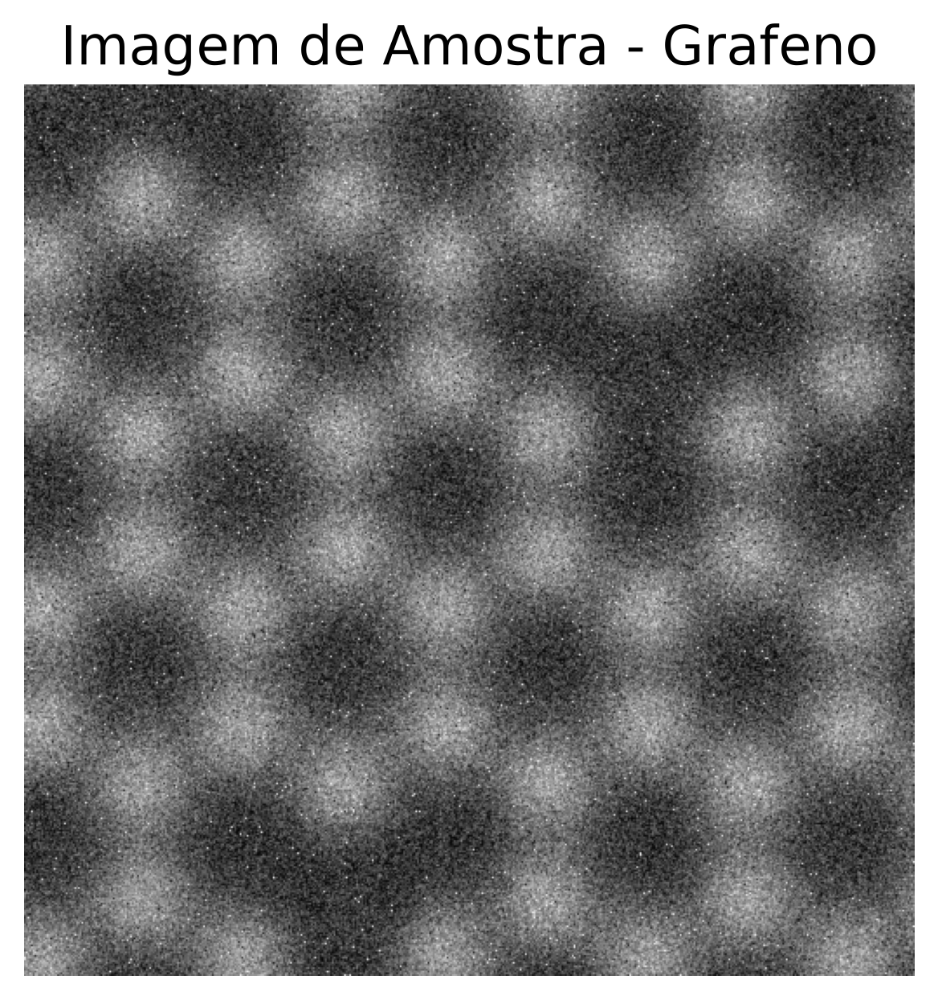

In [9]:
plt.axis("off")
plt.imshow(imagens_teste_grafeno[0,:,:][0], cmap='gray', vmin=0, vmax=1)

plt.title("Imagem de Amostra - Grafeno")

### **U-Net MaxPool Grafeno (Otimizada)**

In [10]:
# Salva a função original
_load_from_bytes_original = torch.storage._load_from_bytes

# Substitui temporariamente por uma versão que força CPU
torch.storage._load_from_bytes = lambda b: torch.load(
    io.BytesIO(b),
    map_location=torch.device("cpu"),
    weights_only=False
)

try:
    with open("../3_Otimização-de-Hiperparâmetros/3_3_Redes-Treinadas/3_3_1_grafeno/U_NetD2_FuzzyPool_grafeno_dados_completos.pkl", "rb") as modelo:
        UNet_grafeno_otimizada = pickle.load(modelo)
finally:
    # Restaura a função original
    torch.storage._load_from_bytes = _load_from_bytes_original

UNet_grafeno_otimizada = UNet_grafeno_otimizada.to("cpu")
UNet_grafeno_otimizada.eval()

UNet_BinariaD2_FP(
  (down1): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(1, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(16, 16, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU6(inplace=True)
    )
  )
  (pool1): FuzzyPooling()
  (down2): DoubleConv(
    (conv): Sequential(
      (0): Conv2d(16, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU6(inplace=True)
    )
  )
  

### Fuzzy Pooling 1

In [11]:
convolucao1 = UNet_grafeno_otimizada.down1(
    imagens_teste_grafeno
)

teste_conv_FP1 = UNet_grafeno_otimizada.pool1(convolucao1)

imagens_conv1 = convolucao1.detach().cpu().numpy()
imagens_pool1 = teste_conv_FP1.detach().cpu().numpy()


# Conjuntos Fuzzy
indices_pool1 = (
    UNet_grafeno_otimizada.pool1.indices
    .detach().cpu().numpy()
)

# Pertinências fuzzy
pertfuzzy_pool1 = (
    UNet_grafeno_otimizada.pool1.matrizes_pi
    .detach().cpu().numpy()
)

In [12]:
print("FUZZY POOLING 1 \n")

i = 0

crms_conv1 = np.zeros((1, 16)) # imagem, canal
crms_fp1 = np.zeros((1, 16))
psnr1 = np.zeros((1, 16)) 
ssim1 = np.zeros((1, 16))

pool1_rsz = restore_size(imagens_pool1, (512, 512))

for c in range(16):
    crms_conv1[i, c] = np.std(imagens_conv1[i, c], correction=0)
    crms_fp1[i, c] = np.std(pool1_rsz[i, c], correction=0)
    
    psnr1[i, c] = peak_signal_noise_ratio(
        imagens_conv1[i, c],
        pool1_rsz[i, c],
        data_range=6
    )

    ssim1[i, c] = structural_similarity(
        imagens_conv1[i, c],
        pool1_rsz[i, c],
        data_range=6
    )

print("Imagem ", 0)
print("Crms Médio (conv): ", round(np.mean(crms_conv1[i]),4))
print("Crms Médio (FP): ", round(np.mean(crms_fp1[i]),4))
print("PSNR Médio: ", round(np.mean(psnr1[i]),4))
print("SSIM Médio: ", round(np.mean(ssim1[i]),4))
print(" ")


FUZZY POOLING 1 

Imagem  0
Crms Médio (conv):  0.375
Crms Médio (FP):  0.3473
PSNR Médio:  35.9157
SSIM Médio:  0.862
 


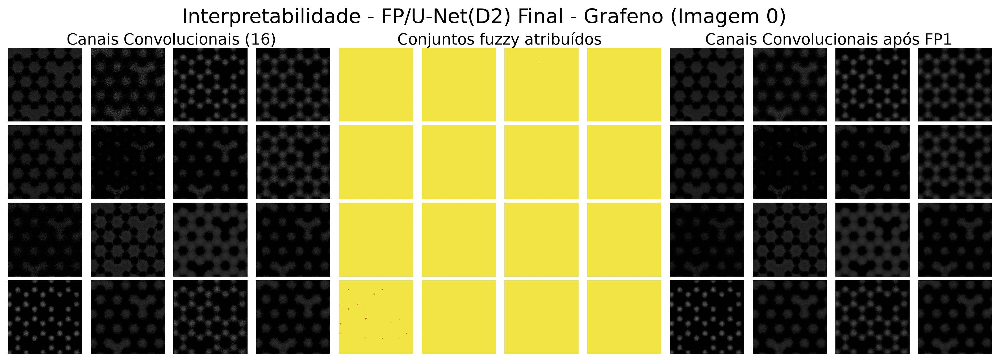

In [13]:
N, Z, _, _, L = indices_pool1.shape

H_pool, W_pool = teste_conv_FP1.shape[-2:]

conjuntos1 = indices_pool1[:, :, 0, 0, :].reshape(
    N, Z, H_pool, W_pool
)

j = 0

fig, axes = plt.subplots(
    4, 12,
    figsize=(16, 5)
)

for i in range(16):

    linha = i // 4
    coluna = i % 4

    # Canais convolucionais
    axes[linha, coluna].imshow(
        imagens_conv1[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna].axis("off")

    # Conjuntos fuzzy atribuídos
    axes[linha, coluna + 4].imshow(
        conjuntos1[j, i],
        cmap=cmap_3,
        vmin=0,
        vmax=2
    )
    axes[linha, coluna + 4].axis("off")

    # Saída após FuzzyPooling
    axes[linha, coluna + 8].imshow(
        imagens_pool1[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna + 8].axis("off")

fig.suptitle(
    f"Interpretabilidade - FP/U-Net(D2) Final - Grafeno (Imagem 0)"
)

fig.text(
    0.255, 0.888,
    "Canais Convolucionais (16)",
    ha="center",
    fontsize=14
)

fig.text(
    0.512, 0.888,
    "Conjuntos fuzzy atribuídos",
    ha="center",
    fontsize=14
)

fig.text(
    0.77, 0.888,
    "Canais Convolucionais após FP1",
    ha="center",
    fontsize=14
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

# Salvar figura
plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/FP1_grafeno_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

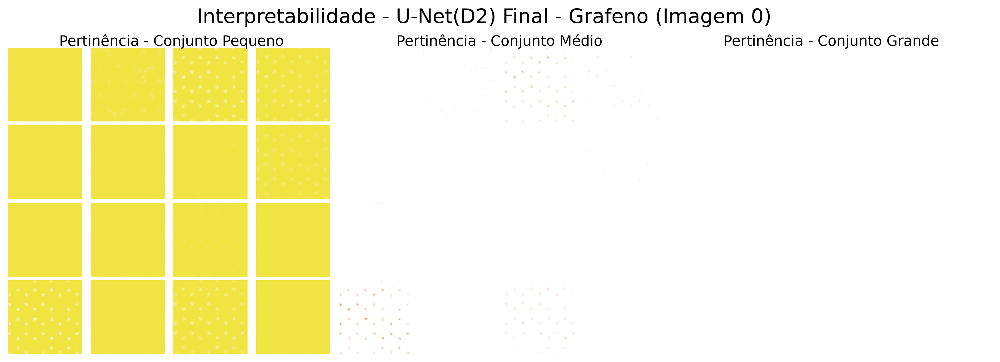

In [14]:
N, Z, V, K, L = pertfuzzy_pool1.shape

H_pool, W_pool = teste_conv_FP1.shape[-2:]

conjuntos1 = []

for c in range(3):

    mu = pertfuzzy_pool1[:, :, c, 0, :].reshape(
        N, Z, H_pool, W_pool
    )

    conjuntos1.append(np.clip(mu, 0, 1))

# Cores dos conjuntos fuzzy (Pequeno, Médio, Grande)
cores_rgb = [to_rgb(cor) for cor in cmap_3.colors]

n_linhas = 4
n_colunas = 4

j = 0

fig, axes = plt.subplots(
    n_linhas,
    3 * n_colunas,
    figsize=(16, 5)
)

# Pertinências fuzzy
for c in range(3):

    for i in range(16):

        linha = i // n_colunas
        coluna = i % n_colunas

        ax = axes[linha, c * n_colunas + coluna]

        mu = conjuntos1[c][j, i]

        rgba = np.zeros((H_pool, W_pool, 4))

        rgba[..., :3] = cores_rgb[c]
        rgba[..., 3] = mu

        ax.imshow(rgba)
        ax.axis("off")

fig.suptitle(
    f"Interpretabilidade - U-Net(D2) Final - Grafeno (Imagem 0)"
)

fig.text(
    0.255,
    0.885,
    "Pertinência - Conjunto Pequeno",
    ha="center",
    fontsize=13
)

fig.text(
    0.512,
    0.885,
    "Pertinência - Conjunto Médio",
    ha="center",
    fontsize=13
)

fig.text(
    0.772,
    0.885,
    "Pertinência - Conjunto Grande",
    ha="center",
    fontsize=13
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

# Salvar figura
plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/int_pertinencia_FP1_grafeno_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

### Fuzzy Pooling 2

In [15]:
convolucao2 = UNet_grafeno_otimizada.down2(teste_conv_FP1)
teste_conv_FP2 = UNet_grafeno_otimizada.pool2(convolucao2)

imagens_conv2 = convolucao2.detach().cpu().numpy()
imagens_pool2 = teste_conv_FP2.detach().cpu().numpy()

# Conjuntos Fuzzy
indices_pool2 = (
    UNet_grafeno_otimizada.pool2.indices
    .detach().cpu().numpy()
)

#Pertinência Fuzzy
pertfuzzy_pool2 = (
    UNet_grafeno_otimizada.pool2.matrizes_pi
    .detach().cpu().numpy()
)

In [16]:
print("FUZZY POOLING 2 \n")

i = 0

crms_conv2 = np.zeros((1, 32)) # imagem, canal
crms_fp2 = np.zeros((1, 32))
psnr2 = np.zeros((1, 32)) 
ssim2 = np.zeros((1, 32))

pool2_rsz = restore_size(imagens_pool2, (256, 256))

for c in range(32):
    crms_conv2[i, c] = np.std(imagens_conv2[i, c], correction=0)
    crms_fp2[i, c] = np.std(pool2_rsz[i, c], correction=0)
    
    psnr2[i, c] = peak_signal_noise_ratio(
        imagens_conv2[i, c],
        pool2_rsz[i, c],
        data_range=6
    )

    ssim2[i, c] = structural_similarity(
        imagens_conv2[i, c],
        pool2_rsz[i, c],
        data_range=6
    )

print("Imagem ", 0)
print("Crms Médio (conv): ", round(np.mean(crms_conv2[i]),4))
print("Crms Médio (FP): ", round(np.mean(crms_fp2[i]),4))
print("PSNR Médio: ", round(np.mean(psnr2[i]),4))
print("SSIM Médio: ", round(np.mean(ssim2[i]),4))
print(" ")

FUZZY POOLING 2 

Imagem  0
Crms Médio (conv):  0.3721
Crms Médio (FP):  0.3418
PSNR Médio:  37.1716
SSIM Médio:  0.9462
 


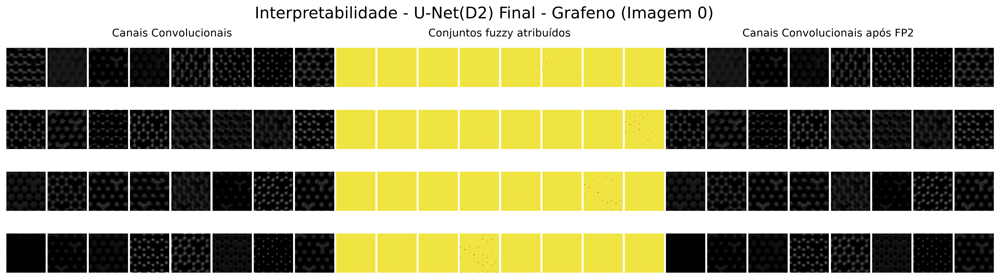

In [17]:
N, Z, _, _, L = indices_pool2.shape
H_pool, W_pool = teste_conv_FP2.shape[-2:]

conjuntos2 = indices_pool2[:, :, 0, 0, :].reshape(
    N, Z, H_pool, W_pool
)

j = 0

fig, axes = plt.subplots(4, 24, figsize=(20, 5))

for i in range(32):

    linha = i // 8
    coluna = i % 8

    # Convoluções
    axes[linha, coluna].imshow(
        imagens_conv2[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna].axis("off")

    # Índices fuzzy
    axes[linha, coluna + 8].imshow(
        conjuntos2[j, i],
        cmap=cmap_3,
        vmin=0,
        vmax=2
    )
    axes[linha, coluna + 8].axis("off")

    # FuzzyPooling
    axes[linha, coluna + 16].imshow(
        imagens_pool2[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna + 16].axis("off")

fig.suptitle(
   "Interpretabilidade - U-Net(D2) Final - Grafeno (Imagem 0)"
)

fig.text(
    0.255,
    0.885,
    "Canais Convolucionais",
    ha="center",
    fontsize=12
)

fig.text(
    0.512,
    0.885,
    "Conjuntos fuzzy atribuídos",
    ha="center",
    fontsize=12
)

fig.text(
    0.77,
    0.885,
    "Canais Convolucionais após FP2",
    ha="center",
    fontsize=12
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/FP2_grafeno_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

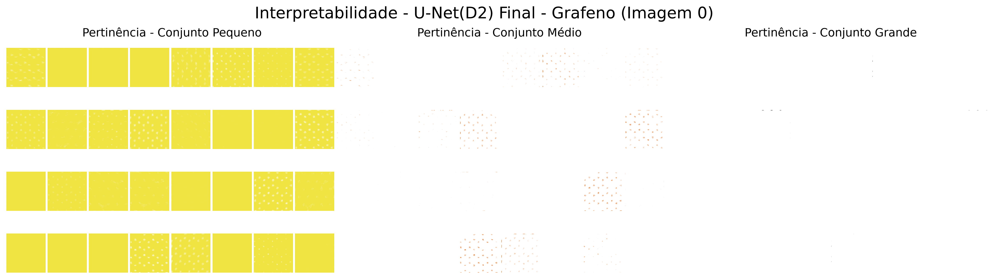

In [18]:
conjuntos2 = []

for c in range(3):

    mu = pertfuzzy_pool2[:, :, c, 0, :].reshape(
        pertfuzzy_pool2.shape[0],
        pertfuzzy_pool2.shape[1],
        H_pool,
        W_pool
    )

    conjuntos2.append(np.clip(mu, 0, 1))

cores_rgb = [to_rgb(cor) for cor in cmap_3.colors]

j = 0

fig, axes = plt.subplots(4, 24, figsize=(20, 5))

for i in range(32):

    linha = i // 8
    coluna = i % 8

    # Pertinências
    for c in range(3):

        ax = axes[linha, coluna + 8 * c]

        rgba = np.zeros((H_pool, W_pool, 4))
        rgba[..., :3] = cores_rgb[c]
        rgba[..., 3] = conjuntos2[c][j, i]

        ax.imshow(rgba)
        ax.axis("off")

fig.suptitle(
    "Interpretabilidade - U-Net(D2) Final - Grafeno (Imagem 0)"
)

fig.text(
    0.255,
    0.885,
    "Pertinência - Conjunto Pequeno",
    ha="center",
    fontsize=13
)

fig.text(
    0.512,
    0.885,
    "Pertinência - Conjunto Médio",
    ha="center",
    fontsize=13
)

fig.text(
    0.772,
    0.885,
    "Pertinência - Conjunto Grande",
    ha="center",
    fontsize=13
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/pertinencia_FP2_grafeno_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

### Fuzzy Pooling 3

In [19]:
convolucao3 = UNet_grafeno_otimizada.down3(teste_conv_FP2)
teste_conv_FP3 = UNet_grafeno_otimizada.pool3(convolucao3)

imagens_conv3 = convolucao3.detach().cpu().numpy()
imagens_pool3 = teste_conv_FP3.detach().cpu().numpy()

# Conjuntos Fuzzy
indices_pool3 = (
    UNet_grafeno_otimizada.pool3.indices
    .detach().cpu().numpy()
)

# Pertinências Fuzzy
pertfuzzy_pool3 = (
    UNet_grafeno_otimizada.pool3.matrizes_pi
    .detach().cpu().numpy()
)

In [20]:
print("FUZZY POOLING 3 \n")

crms_conv3 = np.zeros((1, 64)) # imagem, canal
crms_fp3 = np.zeros((1, 64))
psnr3 = np.zeros((1, 64)) 
ssim3 = np.zeros((1, 64))

pool3_rsz = restore_size(imagens_pool3, (128, 128))

i = 0 

for c in range(64):
    crms_conv3[i, c] = np.std(imagens_conv3[i, c], correction=0)
    crms_fp3[i, c] = np.std(pool3_rsz[i, c], correction=0)
    
    psnr3[i, c] = peak_signal_noise_ratio(
        imagens_conv3[i, c],
        pool3_rsz[i, c],
        data_range=6
    )

    ssim3[i, c] = structural_similarity(
        imagens_conv3[i, c],
        pool3_rsz[i, c],
        data_range=6
    )

print("Imagem ", 0)
print("Crms Médio (conv): ", round(np.mean(crms_conv3[i]),4))
print("Crms Médio (FP): ", round(np.mean(crms_fp3[i]),4))
print("PSNR Médio: ", round(np.mean(psnr3[i]),4))
print("SSIM Médio: ", round(np.mean(ssim3[i]),4))
print(" ")

FUZZY POOLING 3 

Imagem  0
Crms Médio (conv):  0.4135
Crms Médio (FP):  0.3168
PSNR Médio:  30.7992
SSIM Médio:  0.826
 


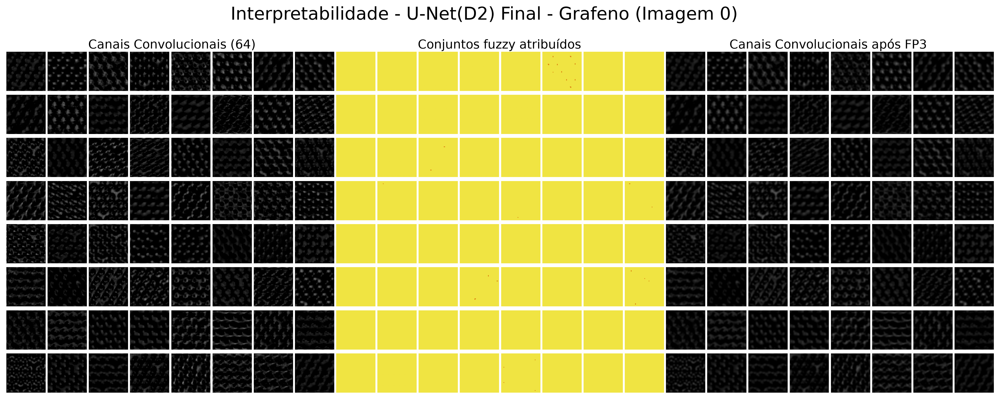

In [21]:
N, Z, _, _, L = indices_pool3.shape
H_pool, W_pool = teste_conv_FP3.shape[-2:]

conjuntos3 = indices_pool3[:, :, 0, 0, :].reshape(
    N, Z, H_pool, W_pool
)

j = 0

fig, axes = plt.subplots(8, 24, figsize=(20, 7))

for i in range(64):

    linha = i // 8
    coluna = i % 8

    # Convoluções
    axes[linha, coluna].imshow(
        imagens_conv3[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna].axis("off")

    # Índices fuzzy
    axes[linha, coluna + 8].imshow(
        conjuntos3[j, i],
        cmap=cmap_3,
        vmin=0,
        vmax=2
    )
    axes[linha, coluna + 8].axis("off")

    # FuzzyPooling
    axes[linha, coluna + 16].imshow(
        imagens_pool3[j, i],
        cmap="gray",
        vmin=0,
        vmax=6
    )
    axes[linha, coluna + 16].axis("off")

fig.suptitle(
    f"Interpretabilidade - U-Net(D2) Final - Grafeno (Imagem 0)",
    fontsize=20
)

fig.text(
    0.255,
    0.885,
    "Canais Convolucionais (64)",
    ha="center",
    fontsize=14
)

fig.text(
    0.512,
    0.885,
    "Conjuntos fuzzy atribuídos",
    ha="center",
    fontsize=14
)

fig.text(
    0.77,
    0.885,
    "Canais Convolucionais após FP3",
    ha="center",
    fontsize=14
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/FP3_grafeno_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

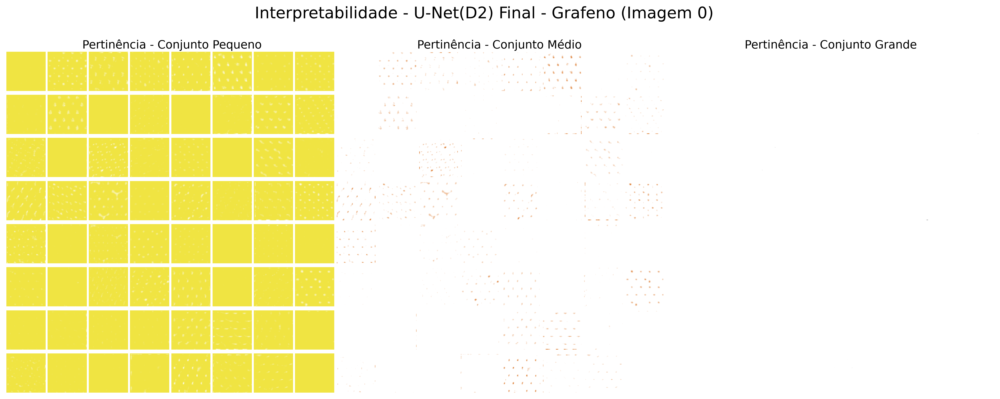

In [22]:
conjuntos3 = []

for c in range(3):

    mu = pertfuzzy_pool3[:, :, c, 0, :].reshape(
        pertfuzzy_pool3.shape[0],
        pertfuzzy_pool3.shape[1],
        H_pool,
        W_pool
    )

    conjuntos3.append(np.clip(mu, 0, 1))

cores_rgb = [to_rgb(cor) for cor in cmap_3.colors]


fig, axes = plt.subplots(8, 24, figsize=(20, 7))

for i in range(64):

    linha = i // 8
    coluna = i % 8

    # Pertinências fuzzy
    for c in range(3):

        ax = axes[linha, coluna + 8 * c]

        rgba = np.zeros((H_pool, W_pool, 4))
        rgba[..., :3] = cores_rgb[c]
        rgba[..., 3] = conjuntos3[c][j, i]

        ax.imshow(rgba)
        ax.axis("off")

fig.suptitle(
    "Interpretabilidade - U-Net(D2) Final - Grafeno (Imagem 0)")

fig.text(
    0.255,
    0.885,
    "Pertinência - Conjunto Pequeno",
    ha="center",
    fontsize=13
)

fig.text(
    0.512,
    0.885,
    "Pertinência - Conjunto Médio",
    ha="center",
    fontsize=13
)

fig.text(
    0.772,
    0.885,
    "Pertinência - Conjunto Grande",
    ha="center",
    fontsize=13
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.05,
    top=0.88
)

plt.savefig(
    f"Imagens_interpretabilidade/{diretorio}/pertinencia_FP3_grafeno_{diretorio}.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)